# This notebook differences two timeseries created from 2 dimensional timeseries
## It visualizes the steps through plots, checks correlation, calculates power spectra
### See notebook 2Dtimeseries_1_Visualization_Properties.ipynb for how to handle 2D timeseries
### Example timeseries shown are real data recorded by a RPG-FFTS spectrometer, but any similar dataset can be used

**Loading necessary packages. Please install packages if not present.**

The data reading, gain matching, differencing and power spectrum functions live in `python_functions/Analysis_functions.py`. The `sys.path` line below makes that folder importable, assuming this notebook is run from its own folder, `example_notebooks/` (Jupyter and VS Code do this by default).

In [1]:
import os
import sys
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from matplotlib.ticker import MaxNLocator

# make the function files in ../python_functions importable
sys.path.insert(0, os.path.abspath(os.path.join('..', 'python_functions')))
from Analysis_functions import read_rpg_spec, gain_match, difference_timeseries, power_spectrum

**The two 2D timeseries files, real data from a noise diode passing through a circuit recorded by a FFT spectrometer**

In [2]:
filename1 = 'RPGFFTSchanA.spec'
filename2 = 'RPGFFTSchanB.spec'

**Loading data into numpy arrays, calibrated to physical units (mW)**

`read_rpg_spec` is specific to the RPG FFTS file format and calibration - adjust it, or write a similar reader, for other data. It returns one row per time stamp and one column per channel.

In [3]:
# integration time per time stamp (s), and number of spectrometer channels
ts = 0.1
chans = 8192

spec1 = read_rpg_spec(filename1, ts=ts, chans=chans)
spec2 = read_rpg_spec(filename2, ts=ts, chans=chans)

# making sure the numbers of time stamps match
nt = min(spec1.shape[0], spec2.shape[0])
spec1 = spec1[:nt]
spec2 = spec2[:nt]

print('{} time stamps, {} channels'.format(*spec1.shape))

764 time stamps, 8192 channels


**Averaging data along 'time' axis - the actual timeseries - averaging over a range of 'channels'**

In [4]:
chani = 1500
chanf = 6500

plsp1 = np.sum(spec1[:,chani:chanf+1],axis=1)/(chanf-chani+1)
plsp2 = np.sum(spec2[:,chani:chanf+1],axis=1)/(chanf-chani+1)

dc1=np.mean(plsp1)
dc2=np.mean(plsp2)

print('DC level of 1 = {}'.format(dc1))
print('DC level of 2 = {}'.format(dc2))

# modify input 2 gain level to input 1 gain level
plsp2 = gain_match(plsp2, plsp1)

DC level of 1 = 3.6173917898221936e-05
DC level of 2 = 3.180175391161488e-05


**Confirming that the two 'channel' averaged timeseries are correlated well**

In [5]:
# Calculating Pearson correlation coefficient

pcc = pearsonr(plsp1,plsp2)

print('Pearson correlation coefficient between the 2 timeseries = {}'.format(pcc[0]))

Pearson correlation coefficient between the 2 timeseries = 0.9376480056917446


**Plotting the two channel averaged timeseries**

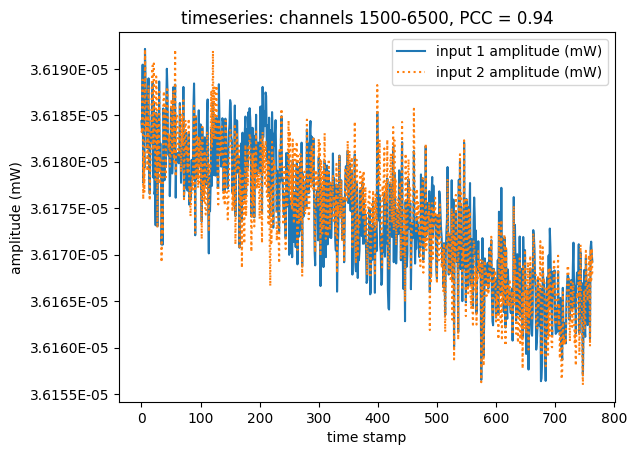

In [6]:
plt.figure()
plt.title('timeseries: channels {}-{}, PCC = {:.2f}'.format(chani,chanf,pcc[0]))
plt.xlabel('time stamp')
plt.ylabel('amplitude (mW)')
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.4E'))
plt.plot(plsp1,label='input 1 amplitude (mW)')
plt.plot(plsp2,':',label='input 2 amplitude (mW)')
plt.legend()
plt.show()

**Fitting out the base trend (dispersion relation), and creating the difference timeseries**

`difference_timeseries` fits a straight line, timeseries 2 = m × timeseries 1 + c, and returns the difference between the line's prediction and timeseries 2, divided by √2.

best fit line: slope = 0.9485, offset = 1.8619E-06 mW


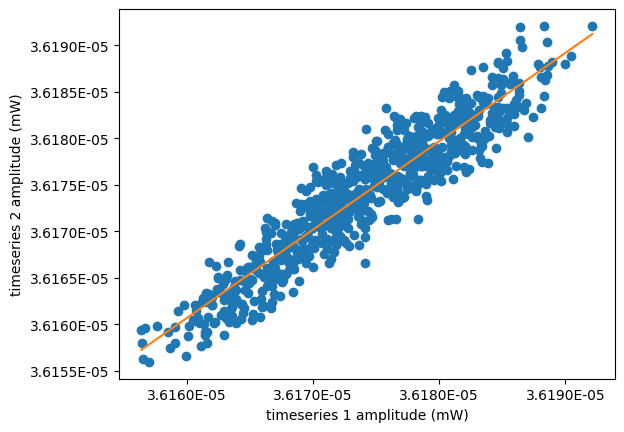

In [7]:
# fitting a straight line to the dispersion relation between the two timeseries, and creating the difference timeseries

dsp, m, c = difference_timeseries(plsp1, plsp2)

print('best fit line: slope = {:.4f}, offset = {:.4E} mW'.format(m, c))

# plotting the dispersion relation along with the best fit

x=np.linspace(plsp1.min(),plsp1.max(),1000)
y=m*x+c

plt.figure()
plt.xlabel('timeseries 1 amplitude (mW)')
plt.ylabel('timeseries 2 amplitude (mW)')
plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%.4E'))
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.4E'))
plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=4))
plt.plot(plsp1,plsp2,'o')
plt.plot(x,y)
plt.draw()

**Plotting the difference timeseries**

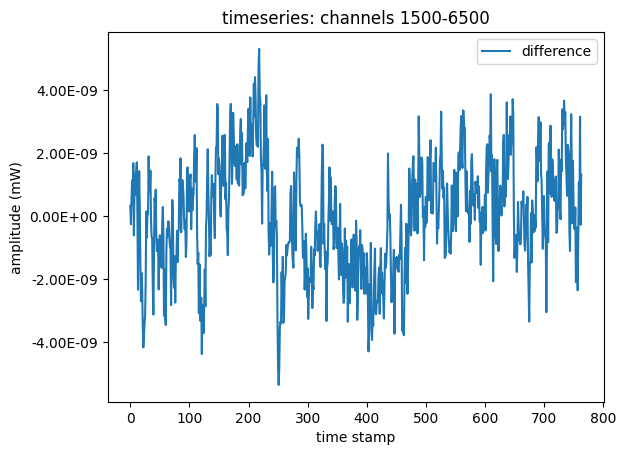

rms variation of difference = 1.7820362009803362e-09


In [8]:
plt.figure()
plt.title('timeseries: channels '+str(chani)+'-'+str(chanf))
plt.xlabel('time stamp')
plt.ylabel('amplitude (mW)')
plt.gca().yaxis.set_major_formatter(FormatStrFormatter('%.2E'))
plt.plot(dsp,label='difference')
plt.legend()
plt.draw()
plt.show()

print('rms variation of difference = {}'.format(np.std(dsp)))

**Calculating and plotting the power spectra of the difference timeseries and comparing it to those of the original timeseries**

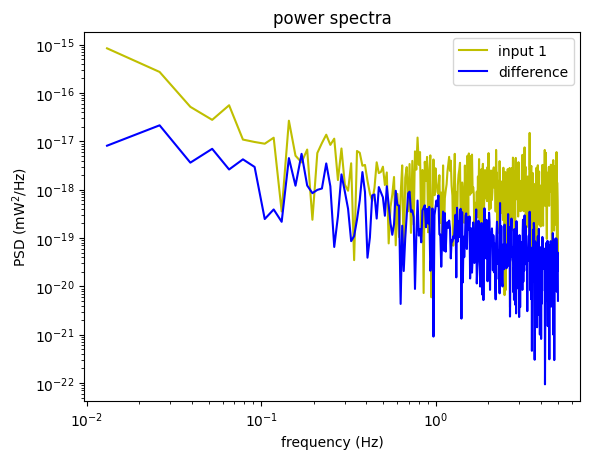

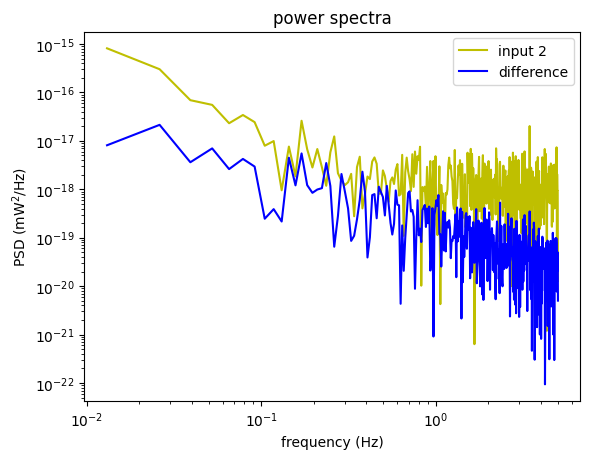

In [9]:
# power spectra of gain-matched inputs

fsp1, Psp1 = power_spectrum(plsp1, ts)
fsp2, Psp2 = power_spectrum(plsp2, ts)

# power spectrum of difference timeseries 

fsp, Psp = power_spectrum(dsp, ts)

plt.figure()
plt.title('power spectra')
plt.xlabel('frequency (Hz)')
plt.ylabel('PSD (mW$^2$/Hz)')
plt.semilogx()
plt.semilogy()
plt.plot(fsp1,Psp1,'-y',label='input 1')
plt.plot(fsp,Psp,'-b',label='difference')
plt.legend()
plt.draw()

plt.figure()
plt.title('power spectra')
plt.xlabel('frequency (Hz)')
plt.ylabel('PSD (mW$^2$/Hz)')
plt.semilogx()
plt.semilogy()
plt.plot(fsp2,Psp2,'-y',label='input 2')
plt.plot(fsp,Psp,'-b',label='difference')
plt.legend()
plt.show()